# Université Paul Sabatier
# M1 IAFA - Foundations of Information Retrieval - 2026

Instructors: Lynda Tamine, Karim Radouane and Ahmed Rayane Kebir

---

💡 Consider developing auxiliary scripts and functions that will enable you to reuse recurring commands in this practical work (PW) and future ones. This would help you keeping good code practice and make debugging easier.


### Attention❗ About TP grading:
🚨 *Code questions*: Fill in the missing code in the corresponding sections (commented code gets the best marks).

🚨 *Open questions*: Write your textual answer as a comment in the corresponding cells.

🚨 *Keep your outputs*: **Empty outputs (notebook or non-executed cells) correspond to 0 points**.

---

# TP 1: Language Modeling and Applications for Information Retrieval and Question-Answering

Language modeling is foundamental in natural language processing (NLP) and information retrieval (IR). Basically speaking, its allows trasforming raw textual data  into vector semantics suitable for computational analysis. Vector semantics based on  TF-IDF (Term Frequency-Inverse Document Frequency), word embeddings, and Transformer-based encoders are widely used for this purpose. These vectors are essential as they enable algorithms to process and analyze text quantitatively, supporting natural language understanding tasks like document similarity, clustering, summarization, question-answering, information retrieval, etc.

# The TREC-COVID Dataset

In this PW, we will focus on a real-world dataset called **TREC-COVID dataset**,  that focuses on documents dealing with COVID-19 and a set of related questions. Each question in the dataset is linked to research papers (documents) that may or may not contain the associated correct answers.


# Objectives of the PW

Through this PW, you will:

1. Analyze the structure and content of the TREC-COVID dataset.
2. Implement word-level vector semantics.
3. Explore geometric patterns in word-level vector semantics.
4. Develop document-level vector semantics.
5. Deploy these vector semantics in downstream tasks, such as question-answering and information retrieval.

### Installations and Imports
> 👉 Before starting working with the Transformers-based models, please select ``T4 GPU`` in the menu: ``Runtime/Change runtime type`` and re-run these 2 cells. **Save your work before changing the runtime type**.

In [ ]:
# Some libraries to use later
!pip install numpy==1.26.4 --force-reinstall
!pip install gensim
!pip install scikit-learn matplotlib
!pip install transformers torch
!pip install datasets
!pip install -U sentence-transformers
!pip install -U accelerate

  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.0 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
shap 0.51.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
cupy-cuda12x 14.0.1 requires numpy<2.6,>=2.0, but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you ha

KeyboardInterrupt: 

In [ ]:
import datasets
import numpy as np
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, precision_score, recall_score

from sklearn.manifold import TSNE
import gensim.downloader as api
from nltk.tokenize import word_tokenize
import nltk

import torch
from transformers import AutoTokenizer, AutoModel
from datasets import Dataset
from tqdm import tqdm
from sentence_transformers import SentenceTransformer

# I. Text Representation: Text pre-processing, vector semantics and similarity.



## 1. Dataset analysis

In this section, we begin by working with a simplified toy version of the TREC-COVID dataset. The data is retrieved from the HuggingFace Datasets library under the name ``jeslev/trec_covid_toyset``, providing a minimal and accessible subset of the full dataset for initial exploration and analysis.

In [ ]:
covid_toyset = datasets.load_dataset('jeslev/trec_covid_toyset')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/542 [00:00<?, ?B/s]

data/rel-00000-of-00001.parquet:   0%|          | 0.00/24.8k [00:00<?, ?B/s]

data/nonrel-00000-of-00001.parquet:   0%|          | 0.00/26.1k [00:00<?, ?B/s]

Generating rel split:   0%|          | 0/25 [00:00<?, ? examples/s]

Generating nonrel split:   0%|          | 0/25 [00:00<?, ? examples/s]

We begin by analyzing the dataset to understand its structure and the type of information it contains.

The dataset is divided into two parts: ``rel`` (relevant) and ``nonrel`` (non-relevant) documents to answer a given question. Since both parts share the same structural format, we will focus our analysis on ``rel``.

First, we list all the columns (features) in the dataset to get an overview of the available data.

In [ ]:
covid_toyset['rel'].features

{'query-id': Value('int64'),
 'corpus-id': Value('string'),
 'score': Value('int64'),
 'document': Value('string'),
 'text': Value('string')}

####  Question ✍ OK

Describe what each column means according to your interpretation. Which column represents the questions?

**ANSWER**:

query-id: This column likely represents a unique identifier for each question or query.

corpus-id: This column probably identifies a specific document within the corpus.

score: This numerical value indicates the relevance of a document to a given query. A higher score would typically mean greater relevance.

document: This column contains the textual content of the document (e.g., research paper excerpts).

text: This column represents the questions themselves.

####  Question ✍ OK

List all the questions and compute the total number of questions.

In [ ]:
#### Your code here

list_unique_queries = covid_toyset['rel'].data['text'] # List of ALL questions initially
list_unique_queries = list(set(list_unique_queries)) # Get UNIQUE questions

print(f"All unique questions: {list_unique_queries}")
print(f"Total number of unique questions: {len(list_unique_queries)}")

All unique questions: [<pyarrow.StringScalar: 'what are the benefits and risks of re-opening schools in the midst of the COVID-19 pandemic?'>, <pyarrow.StringScalar: 'are there serological tests that detect antibodies to coronavirus?'>, <pyarrow.StringScalar: 'are there any clinical trials available for the coronavirus'>, <pyarrow.StringScalar: 'what type of hand sanitizer is needed to destroy Covid-19?'>, <pyarrow.StringScalar: 'what kinds of complications related to COVID-19 are associated with hypertension?'>]
Total number of unique questions: 5


####  Question ✍ OK
Similarly, compute the total number of documents available for each part (``rel`` and ``nonrel``).

Set a variable ``all_docs`` containing both documents present in both parts.

In [ ]:
#### Your code here

rel_docs = list(covid_toyset['rel'].data['document'])
nonrel_docs = list(covid_toyset['nonrel'].data['document'])

all_docs = rel_docs + nonrel_docs

print(f"Total number of documents in 'rel' part: {len(rel_docs)}")
print(f"Total number of documents in 'nonrel' part: {len(nonrel_docs)}")
print(f"Total number of documents in all_docs: {len(all_docs)}")

Total number of documents in 'rel' part: 25
Total number of documents in 'nonrel' part: 25
Total number of documents in all_docs: 50


####  Question ✍ OK
Compute the average length of documents in terms of words (and the std dev).

In [ ]:
#### Your code here

# Compute the average length of documents (# words)
def compute_stats(list_of_sentences):

  lengths = [len(str(doc).split()) for doc in list_of_sentences]
  average_length = np.mean(lengths)
  std_dev_length = np.std(lengths)

  print(f"Average document length (words): {average_length:.2f}")
  print(f"Standard deviation of document length: {std_dev_length:.2f}")

compute_stats(all_docs)

Average document length (words): 151.62
Standard deviation of document length: 109.68


####  Question ✍ OK
Compute the average length (and the std dev) of the questions.

**Hint**: Use the functions np.mean and np.std

In [ ]:
#### Your code here

def compute_stats_questions(list_of_questions):

  lengths = [len(str(question).split()) for question in list_of_questions]
  average_length = np.mean(lengths)
  std_dev_length = np.std(lengths)

  print(f"Average question length (words): {average_length:.2f}")
  print(f"Standard deviation of question length: {std_dev_length:.2f}")

compute_stats_questions(list_unique_queries)

Average question length (words): 11.00
Standard deviation of question length: 2.61


####  Question ✍ OK
Furthermore, we evaluate the term distribution of the collection.

Complete the following function. For the given input `tokens`, you need to compute the frequency of each token, and sort them in decreasing order of frequency.

You need to compute both, the list of tokens (`ranks`, list of string) and their frequencies (`frequencies`, list of int). You can use the `Counter` object from Python and the `most_common()` function.

In [ ]:
#### Your code here

# Term distribution
def compute_term_frequency(list_of_sentences):

  def preprocess_text(text):
    return str(text).lower().split()

  tokens = []
  for doc in list_of_sentences:
    tokens.extend(preprocess_text(doc))

  # Compute Term Frequencies and
  # Rank Terms and Prepare for Visualization
  token_counts = Counter(tokens)
  sorted_tokens = token_counts.most_common()
  ranks = [token for token, count in sorted_tokens]
  frequencies = [count for token, count in sorted_tokens]

  # Create Log-Log Plot
  plt.figure(figsize=(8, 6))
  plt.plot(ranks, frequencies, marker='o', linestyle='-', label='Term Distribution')
  plt.xscale('log')
  plt.yscale('log')
  plt.title("Term Distribution TREC-COVID")
  plt.xlabel("Rank (log scale)")
  plt.ylabel("Frequency (log scale)")
  plt.grid(True, which="both", linestyle="--", linewidth=0.5)
  plt.legend()
  plt.show()

In [ ]:
# Our term distribution inspection consists of documents and questions,
# we keep trace of an index to identify them.
doc_2_id = {}
my_mini_corpus = []
for _id, single_doc in enumerate(all_docs + list(list_unique_queries)):
  my_mini_corpus.append(single_doc)
  doc_2_id[single_doc] = _id

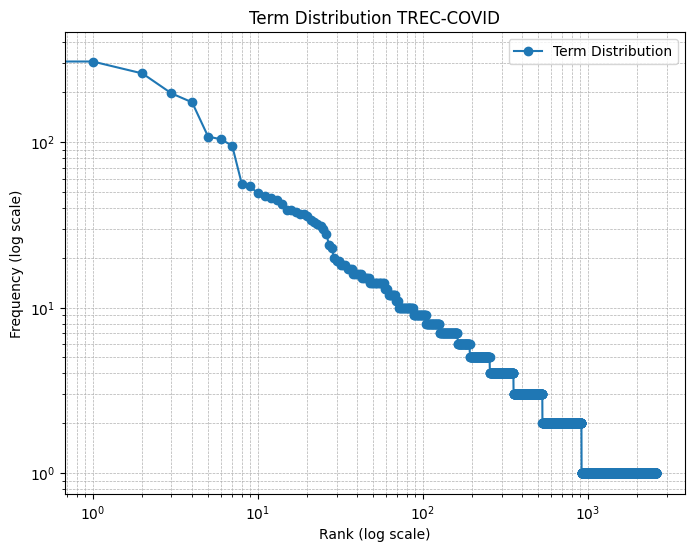

In [ ]:
compute_term_frequency(my_mini_corpus)

###  Question ✍ OK
Analyze the figure and provide a possible interpretation

**ANSWER**:

The figure shows the term frequency against term rank.

Shape of the Curve: I think each point at the head of curve represent a word that appears very frequently, while a large number of words at the tail of the curve represent the words that appear very rarely.

Implication: This distribution means that the corpus (which combines documents and questions from TREC-COVID) contains a small set of highly common words (like articles, prepositions, or domain-specific common terms such as "covid", "patients") that account for a significant portion of the total word occurrences. Moreover, there's a vast vocabulary of less common, more specific terms that appear only once or a few times.

*Notes personnelles: Zipf's law*

## 2. Word-level vector semantics

Text can be represented as vectors at various levels of granularity. In this section, we focus on implementing and working with word-level vector semantics, exploring both sparse and dense approaches (refer to the class resources for more details).

We will examine three key methods for representing vector semantics: TF-IDF, Word Embeddings, and Transformers (BERT)-based representations.


 ### a) TF-IDF (Sparse vector semantics)

The Term Frequency-Inverse Document Frequency (TF-IDF) based vector semantics  transforms text into vectors by quantifying the importance of terms within a a document and corpus.

Using the ``TfidfVectorizer`` from the Sklearn library, we can easily implement this type of vectors. The input to the vectorizer is the corpus (a collection of documents and questions as textual information). The output is a matrix where each row corresponds to a document, and each column represents a unique term in the corpus, collectively known as the ``vocabulary``. The matrix values indicate the TF-IDF score for each term in a document.

To represent a specific word numerically, we extract the corresponding column from the matrix. Below, we demonstrate how to implement this method using the toyset and obtain a single word's representation:



In [ ]:
def get_tfidf_representations(my_corpus):
  vectorizer = TfidfVectorizer()
  # Convert all elements to standard Python strings before fitting
  processed_corpus = [str(doc) for doc in my_corpus]
  # Fit and Transform the Corpus
  tfidf_matrix = vectorizer.fit_transform(processed_corpus)
  return vectorizer, tfidf_matrix

def get_tfidf_word(tfidf_matrix, word_to_index, word):
  if word not in word_to_index:
    raise ValueError("Not in the vocabulary.")
  return tfidf_matrix[:, word_to_index[word]].toarray().flatten()

def plot_single_points(all_words, word_to_index, vis_2d):
  # Plot representation of each word
  plt.figure(figsize=(12, 8))
  for word in all_words:
      i = word_to_index[word]
      x, y = vis_2d[i, 0], vis_2d[i, 1]
      plt.scatter(x, y, color='blue', s=50)
      plt.text(x + 0.1, y + 0.1, word, fontsize=10)

  plt.title("Word Vector Representations", fontsize=14)
  plt.xlabel("t-SNE X", fontsize=12)
  plt.ylabel("t-SNE Y", fontsize=12)
  plt.grid(True)
  plt.show()

In [ ]:
tdidf_representations, tfidf_matrix = get_tfidf_representations(my_mini_corpus)
vocab = tdidf_representations.get_feature_names_out()

We visualize the TF-IDF Matrix. We observe that we have as many rows as documents in our corpus. In the column names, we observe the vocabulary (words) considered by this method.

In [ ]:
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tdidf_representations.get_feature_names_out())
# Display the TF-IDF Representation
print("TF-IDF Document Representation:")
print(tfidf_df)

TF-IDF Document Representation:
         000  001456       002       008       009        01       017  \
0   0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
1   0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
2   0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
3   0.000000   0.000  0.000000  0.050279  0.000000  0.000000  0.000000   
4   0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
5   0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
6   0.000000   0.046  0.000000  0.000000  0.000000  0.000000  0.000000   
7   0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
8   0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
9   0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
10  0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
11  0.000000   0.000  0.000000  0.000000  0.000000  0.000000  0.000000   
12  0.

The vector semantics of words can be visualized in a 2D graph using dimensionality reduction techniques. Each word is mapped to a specific point in the space, providing a visual representation of their relationships and distribution.

We obtain these representations with the following lines using the ``TSNE`` method. For our example, we examine 4 words: ``masking``, ``face``, ``gloves``, ``hands``.

Please note that ``masking`` refers to ``mask``. However, in our available vocabulary from TF-IDF, ``mask`` does not exist.

In [ ]:
# Perform t-SNE to reduce dimensions to 2D from TD-IDF matrix
tsne_tfidf = TSNE(n_components=2, random_state=42, perplexity=5, init='random', learning_rate=200)
tfidf_2d = tsne_tfidf.fit_transform(tfidf_matrix.T.toarray())  # Transpose to work with word vectors
# Get vocabulary (words and their indices)
word_to_index = {word: i for i, word in enumerate(vocab)}

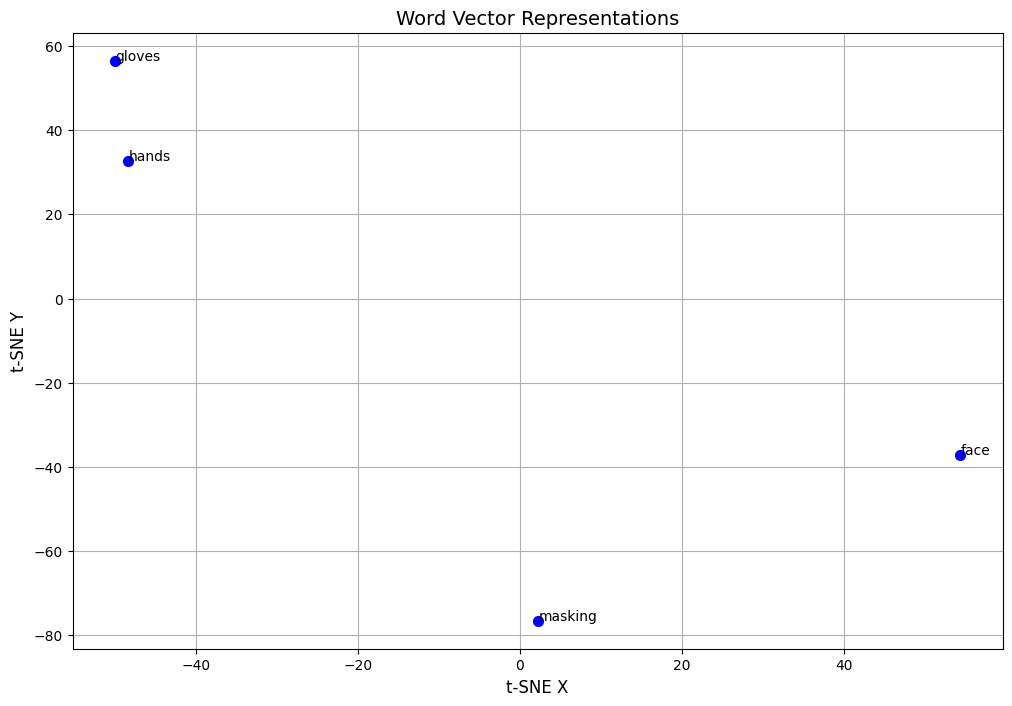

In [ ]:
all_words = ["masking", "face", "gloves", "hands"]
plot_single_points(all_words, word_to_index, tfidf_2d)

####  Question ✍ OK

Implement two other variants of TF-IDF (as presented in class). Then, visualize the representations of the same words. Do they change? Why?


**Hint:**
- For one variantion you can set the parameter ``use_idf``, to omit IDF values.
- For a second variation, you can use ``norm=None`` to avoid normalization, and use the max tf instead (to implement the TF_MAX version)

Visualization Variant 1 (TF only - No IDF):


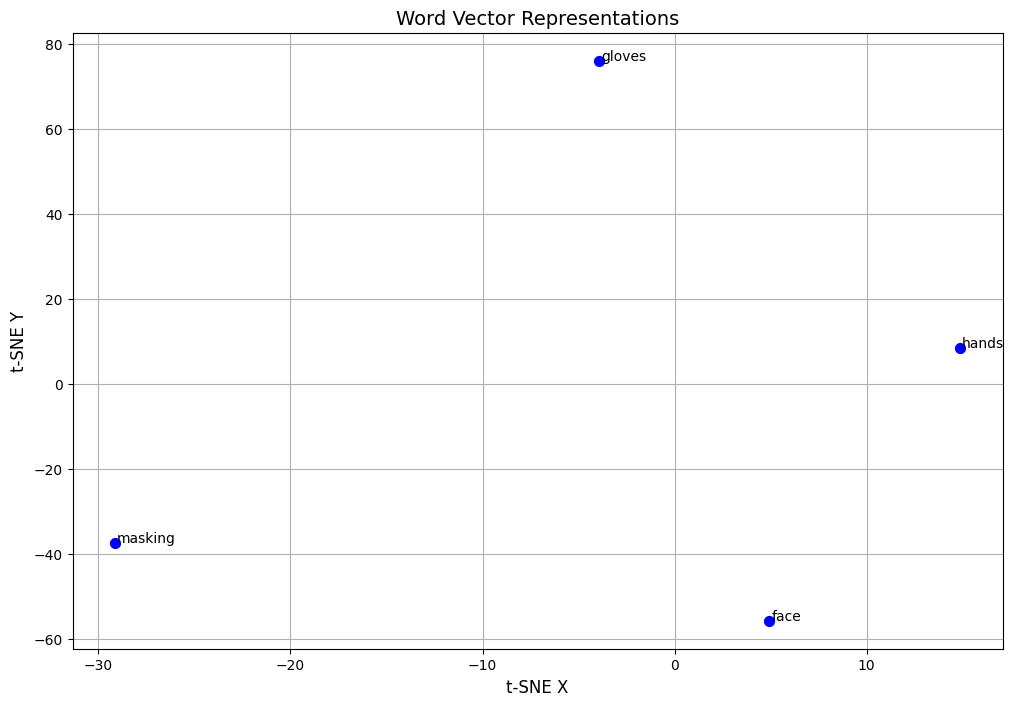

Visualization Variant 2 (No Normalization - Raw TF-IDF):


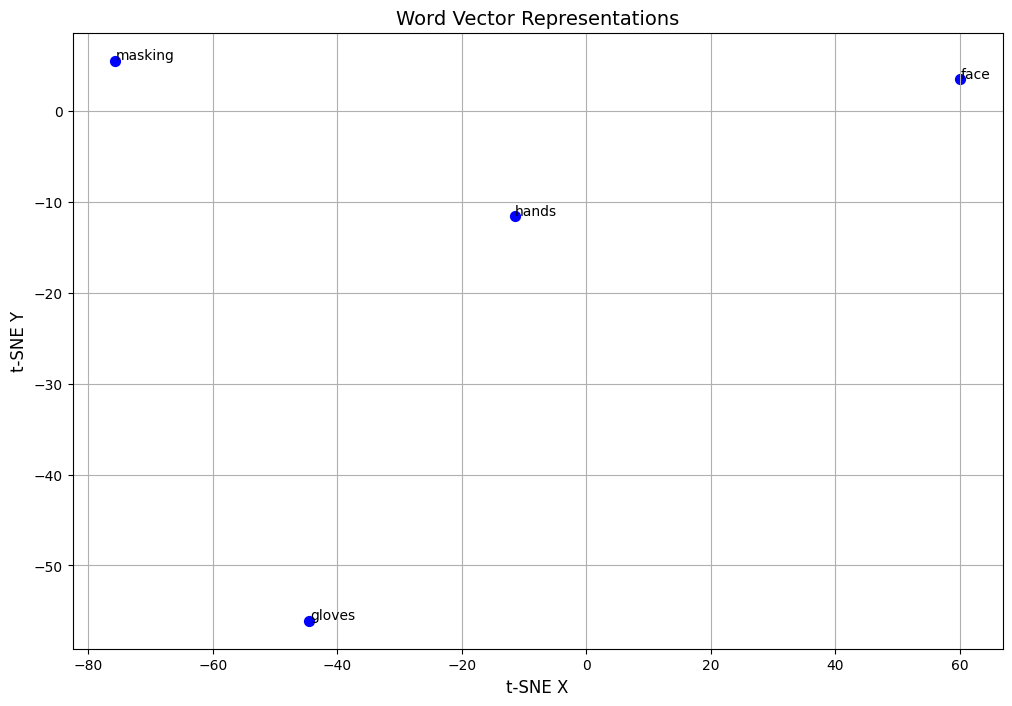

In [ ]:
#### Your code here

# Preprocess to ensure all elements are strings
processed_mini_corpus = [str(doc) for doc in my_mini_corpus]

all_words = ["masking", "face", "gloves", "hands"]

# VARIANT 1: TF only (No IDF)
# This means common words across the corpus are not penalized.
vectorizer_v1 = TfidfVectorizer(use_idf=False, norm='l2')
matrix_v1 = vectorizer_v1.fit_transform(processed_mini_corpus)

# Apply t-SNE to project high-dimensional TF vectors into 2D space
# Note: We transpose the matrix (matrix_v1.T) to get word embeddings instead of document embeddings
tsne_v1 = TSNE(n_components=2, random_state=42, perplexity=5, init='random', learning_rate=200)
tfidf_2d_v1 = tsne_v1.fit_transform(matrix_v1.T.toarray())
word_to_index_v1 = {word: i for i, word in enumerate(vectorizer_v1.get_feature_names_out())}

# Display results for Variant 1
print("Visualization Variant 1 (TF only - No IDF):")
plot_single_points(all_words, word_to_index_v1, tfidf_2d_v1)


# VARIANT 2: No Normalization (Raw counts * IDF)
# In this case, the vector magnitude depends strictly on term frequency and document length.
vectorizer_v2 = TfidfVectorizer(norm=None, use_idf=True)
matrix_v2 = vectorizer_v2.fit_transform(processed_mini_corpus)

# Apply t-SNE for Variant 2
tsne_v2 = TSNE(n_components=2, random_state=42, perplexity=5, init='random', learning_rate=200)
tfidf_2d_v2 = tsne_v2.fit_transform(matrix_v2.T.toarray())
word_to_index_v2 = {word: i for i, word in enumerate(vectorizer_v2.get_feature_names_out())}

# Display results for Variant 2
print("Visualization Variant 2 (No Normalization - Raw TF-IDF):")
plot_single_points(all_words, word_to_index_v2, tfidf_2d_v2)

**ANSWER**:

Yes, the representations change significally in both cases.

Impact of IDF (Variant 1): When IDF is removed, words that are frequent across the entire corpus (like "covid" or "patient") keep a high weight. In standard TF-IDF, these words are penalized because they are not discriminative.

Impact of Normalization (Variant 2): By setting norm=None, we stop scaling the vectors to a unit length (L2). In this version, a word appearing 5 times in a very short document and 5 times in a very long document will have the same raw weight, but their relative importance within their respective documents is different. Without normalization, document length heavily biases the results, and t-SNE shows different spatial distributions because the absolute magnitudes of the vectors vary greatly.

### b) Word-embeddings (dense vector semantics)

A dense representation of vector semantics is **word embeddings**, which leverages neural networks to capture deep meanings and relationships between words. These embeddings represent each word as a vector in a continuous space, enabling a deeper understanding of linguistic patterns and relationships.

Pre-trained word vectors or static embeddings can be downloaded and used directly, simplifying implementation. For example, the following code demonstrates how to download pre-trained Word2Vec embeddings, such as those trained on the Google News dataset:



In [ ]:
def get_word_embeddings():
  # Download and load a pre-trained Word2Vec model
  nltk.download('punkt_tab')
  model = api.load("word2vec-google-news-300")
  return model

def get_w2v_vector(word, model):
  if word in model:
    return model[word]
  else:
    return "Not in vocabulary"

In [ ]:
w2v_model = get_word_embeddings()

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


[==================================================] 100.0% 1662.8/1662.8MB downloaded


####  Question ✍ OK
Obtain the vocabulary of these models (you can use the `key_to_index` attribute).

Compare the vocabulary size between TF-IDF and Word2Vec. Explain why there are these differences

In [ ]:
#### Your code here

tfidf_vocab = tdidf_representations.get_feature_names_out()
w2v_vocab = w2v_model.key_to_index.keys()

print(f"TF-IDF vocabulary size: {len(tfidf_vocab)}")
print(f"Word2Vec (Google News) vocabulary size: {len(w2v_vocab)}")

TF-IDF vocabulary size: 2071
Word2Vec (Google News) vocabulary size: 3000000


**ANSWER:**

The difference comes from the fact that words that appear in similar contexts have similar meanings:

TF-IDF (Local & Sparse): In the small corpus, if the word "mask" only appears in 2 documents and "respirator" appears in 2 others, TF-IDF will see 0 similarity between them. It only cares about exact keyword matches within our 2071 words.

Word2Vec (Global & Dense): It was trained on 3 million words from Google News, it already "knows" that "mask" and "respirator" are used in similar contexts globally. Even if the mini-corpus is tiny, Word2Vec brings in "external knowledge" that allows it to understand synonyms that TF-IDF completely misses.

For fair comparison, we will keep the vocabulary from TF-IDF into Word2Vec.

This code will filter only the words existing on TF-IDF from Word2Vec

In [ ]:
emb_w2v = []
vocab_w2v = []
for word in vocab:
  if word in w2v_model:
    emb_w2v.append(w2v_model[word])
    vocab_w2v.append(word)

w2v_to_index = {}
for i, word in enumerate(vocab_w2v):
  w2v_to_index[word] = i

In [ ]:
# Perform t-SNE to reduce dimensions to 2D
tsne_w2v = TSNE(perplexity=15, n_components=2, init='pca', n_iter=2000, random_state=42)
w2v_2d = tsne_w2v.fit_transform(np.array(emb_w2v))  # Transpose to work with word vectors

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Similar to the previous method, we visualize the representations of the selected words using a 2D plot.

This visualization reveals that the model provides distinct representations and alters the relative distances between points, reflecting the semantic relationships captured by the embeddings.

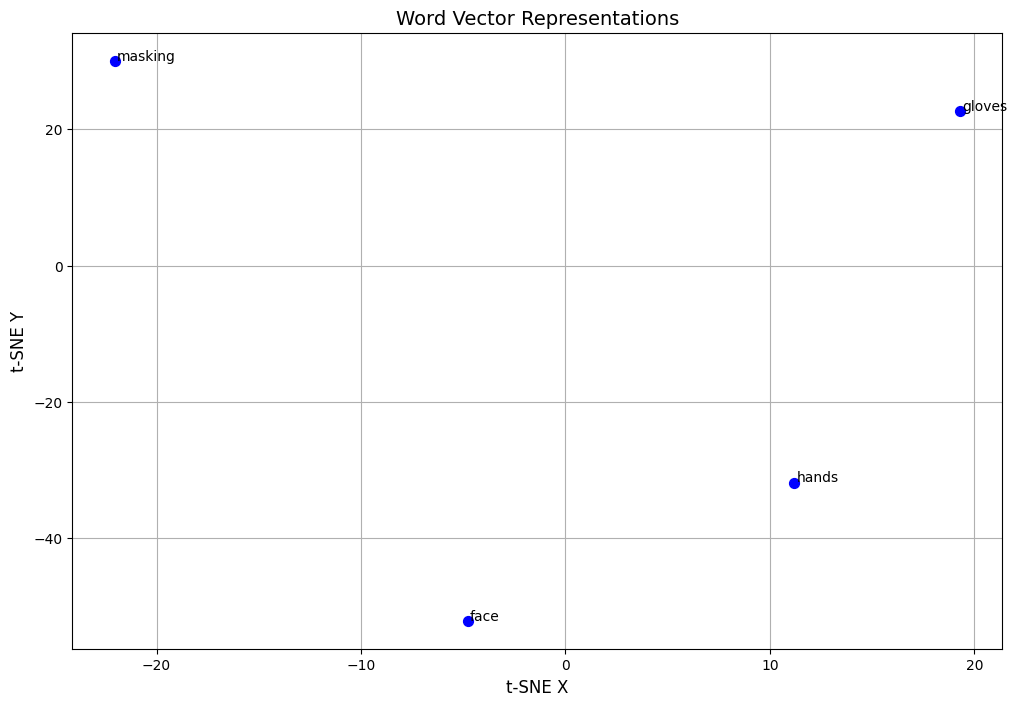

In [ ]:
all_words  = ["masking", "face", "gloves", "hands"]
plot_single_points(all_words, w2v_to_index, w2v_2d)

### c) Transformers-based representation (BERT)


Another powerful language model for representing words and sentences in context is the Transformer-based encoder, such as BERT (Bidirectional Encoder Representations from Transformers). Unlike pre-trained word embeddings like Word2Vec, BERT employs a deep learning model based on the Transformer architecture to generate contextual embeddings.

For this task, we will use the pre-trained Bi-Encoder model, specifically the ``all-MiniLM-L6-v2``, which is available on the HuggingFace hub. Transformer-based models introduce a special token called the [CLS] token (Classification token). This token is appended to the beginning of every input, and the vector corresponding to this token, after processing through the BERT model, captures the contextualized information of the entire input sequence (see your course).

The following code loads the model from HuggingFace. We also use the ``encode`` method from the ``SentenceTransformer`` library to obtain the model representations directly.

In [ ]:
model_name = 'sentence-transformers/all-MiniLM-L6-v2'  # You can use any model available
enc_model = SentenceTransformer(model_name)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
emb_enc = enc_model.encode(vocab)
vocab_enc = [word for word in vocab]

enc_to_index = {}
for i, word in enumerate(vocab_enc):
  enc_to_index[word] = i

####  Question ✍ OK
Similarly, compute the 2D-representations

In [ ]:
# Perform t-SNE to reduce dimensions to 2D
tsne_enc = TSNE(perplexity=15, n_components=2, init='pca', n_iter=2000, random_state=42)
enc_2d = tsne_enc.fit_transform(np.array(emb_enc))

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


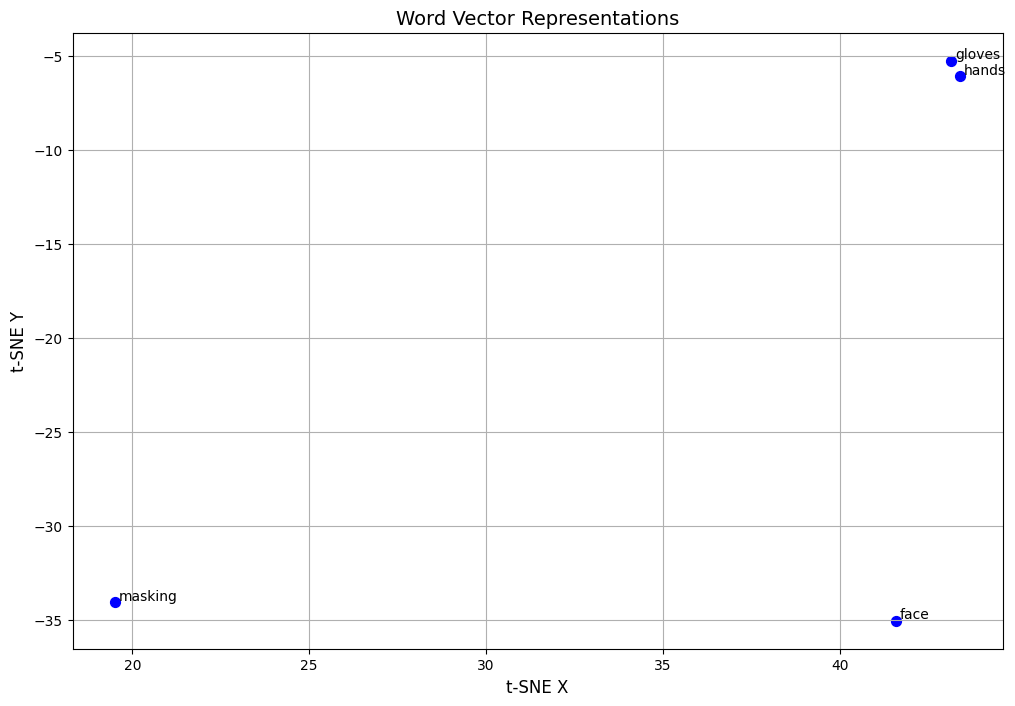

In [ ]:
all_words  = ["masking", "face", "gloves", "hands"]
plot_single_points(all_words, enc_to_index, enc_2d)

####  Question ✍ OK
Analyze the 3 graphic representations from different methods. Why do different methods have different representations? Which one is the best and why?


**Answer**:

- Comparison of Representations:

TF-IDF: The words appear very spread out or grouped only if they literally appear in the same documents. It's a "sparse" representation based on exact counts.

Word2Vec: The words "masking" and "face", "gloves" and "hands" start forming clearer clusters. This is because Word2Vec uses "static" semantic proximity learned from a massive general corpus.

BERT (SBERT): The clusters are most coherent. BERT captures not just the meaning of the word but also its typical usage in medical or safety contexts (especially if using a model like BioBERT). I found weird that "face" was so separated from "masking" but as I said, it could be because they "face" is more commonly used without "masking"


- Why are they different?
The underlying logic is different for each:

TF-IDF is lexical: it only knows about word overlap in our specific data.

Word2Vec is distributed: it uses the context of surrounding words but gives one "average" vector per word regardless of the sentence.

BERT is attentional/contextual: it uses the Transformer architecture to look at the entire sentence structure, leading to much richer, high-dimensional vectors.


- Which one is the best?
For a search engine or QA system, BERT (SBERT) is generally the best.

It solves the "vocabulary mismatch" problem better than TF-IDF (it knows "gloves" and "protection" are related).

It captures nuance better than Word2Vec. While Word2Vec is great for general analogies, BERT is much more powerful for understanding the actual intent behind a user's query in a specific domain like COVID-19.

## 2. Geometric patterns of vector semantics (Geometric analogies)

We will explore the spatial relationships between word representations in a a geometric space. By analyzing these geometric patterns, we can gain insights into how different words are positioned relative to each other, revealing semantic similarities and distances. This exploration helps us understand the structure of the embeddings and their ability to capture meaning and context. We will visualize these semantic relationships using dimensionality reduction techniques used before.

Our analysis involves given three words (for example: ``masking``, ``face``, ``gloves``), where we aim to satisfy the equation:
> ``vector(masking) - vector(face) = vector(gloves) - vector(?)``

This equation seeks to capture the relationship between ``masking`` and ``face``, and infer the corresponding word for ``gloves`` (expected output: ``hands``), based on the shared contextual relationship between body position and usage.

The following function, ``perform_analogy``, takes as input three words and their corresponding vector representations, along with a matrix containing all the vectors from the vocabulary of a specific method (``matrix_vecs``). The function computes the vector closest to the expected output, by calculating the vector:
> ``vector(x) = vector(face) - vector(masking) + vector(gloves)``

and identifying the closest match.


####  Question ✍ OK
Complete the function. The missing part is to compute the most similar words, excluding the input words, from the variable `similarities`.

You should print the `top_k` most similar words.

In [ ]:
# Function to compute analogies
def perform_analogy(vocab, all_words, all_vecs, matrix_vecs, top_k=3):
    """
    word_a is to word_b as word_c is to ?
    Formula: vector(word_d) ≈ vector(word_b) - vector(word_a) + vector(word_c)
    """
    word_a, word_b, word_c = all_words
    vec_a, vec_b, vec_c = all_vecs

    # Compute the analogy vector
    analogy_vector = vec_b - vec_a + vec_c
    # Compute cosine similarity with all other words
    similarities = cosine_similarity(analogy_vector.reshape(1, -1), matrix_vecs).flatten()

  # Find the most similar word (excluding the input words)

    #### Your code here

    # Get indices of the similarities in descending order (highest score first)
    # [::-1] reverses the array returned by argsort
    sorted_indices = np.argsort(similarities)[::-1]

    results = []
    for idx in sorted_indices:
        word = vocab[idx]

        # Exclude the input words (word_a, word_b, word_c)
        if word not in all_words:
            results.append((word, similarities[idx]))

        # We stop when we have found 'top_k' results
        if len(results) == top_k:
            break

    # Printing the top_k results as requested
    print(f"Top {top_k} results for the analogy '{word_a}' is to '{word_b}' as '{word_c}' is to:")
    for i, (word, score) in enumerate(results):
        print(f" -> {word} (similarity: {score:.4f})")

    return results

We compute the candidates for our analogy using the **TF-IDF** method

In [ ]:
# vector(word_d) - vector(word_c) ≈ vector(word_b) - vector(word_a)
# TF-IDF
all_words = "masking", "face", "gloves"
all_vecs = []
for word in all_words:
  all_vecs.append(get_tfidf_word(tfidf_matrix, word_to_index, word))
matrix_vecs = tfidf_matrix.T # All embeddings

perform_analogy(vocab, all_words, all_vecs, matrix_vecs, top_k=3)

Top 3 results for the analogy 'masking' is to 'face' as 'gloves' is to:
 -> lockdown (similarity: 0.7968)
 -> emergencies (similarity: 0.7968)
 -> purpose (similarity: 0.7968)


[('lockdown', 0.796834279520442),
 ('emergencies', 0.796834279520442),
 ('purpose', 0.796834279520442)]

Similarly, we compute the candidate using the **Word Embeddings** previously computed

In [ ]:
# Word embeddings
all_words = "masking", "face", "gloves"
all_vecs = []
for word in all_words:
  all_vecs.append(get_w2v_vector(word, w2v_model))
# All embeddings
matrix_vecs = emb_w2v #np.array([ w2v_model[word] for word in vocab])
perform_analogy(vocab_w2v, all_words, all_vecs, matrix_vecs, top_k=3)

Top 3 results for the analogy 'masking' is to 'face' as 'gloves' is to:
 -> hands (similarity: 0.3574)
 -> towels (similarity: 0.3426)
 -> faced (similarity: 0.3399)


[('hands', 0.35735393), ('towels', 0.34259307), ('faced', 0.33992514)]

Lastly, we do the same with the **Transformers-based** methods

In [ ]:
# Encoder
all_words = "masking", "face", "gloves"
all_vecs = enc_model.encode(all_words)
# All embeddings
matrix_vecs = emb_enc
perform_analogy(vocab_enc, all_words, all_vecs, matrix_vecs, top_k=3)

Top 3 results for the analogy 'masking' is to 'face' as 'gloves' is to:
 -> hands (similarity: 0.6328)
 -> hand (similarity: 0.5952)
 -> body (similarity: 0.4943)


[('hands', 0.6327723), ('hand', 0.5951767), ('body', 0.4942998)]

####  Question ✍ OK
Compute the top-5 closest word that satisfy the analogy for each method:

 "patient"-"hospital" = "children"- "?"

 > Ideally, we can imply a relation of 'goes to', 'belongs to'. A possible value for "?" is "school" or similar words.

In [ ]:
#### Your code here

words_test = ["patient", "hospital", "children"]

# 1. TF-IDF
vecs_tfidf = [get_tfidf_word(tfidf_matrix, word_to_index, w) for w in words_test]
print("TF-IDF Result:")
perform_analogy(vocab, words_test, vecs_tfidf, tfidf_matrix.T.toarray())

# 2. Word Embedding (Word2Vec)
vecs_w2v = [w2v_model[w] for w in words_test if w in w2v_model]
print("\nWord Embeddings Result:")
perform_analogy(vocab_w2v, words_test, vecs_w2v, np.array(emb_w2v))

# 3. Encoders (SBERT/BERT)
vecs_enc = [emb_enc[enc_to_index[w]] for w in words_test]
print("\nEncoders Result:")
perform_analogy(vocab_enc, words_test, vecs_enc, np.array(emb_enc))

TF-IDF Result:
Top 3 results for the analogy 'patient' is to 'hospital' as 'children' is to:
 -> open (similarity: 0.8939)
 -> keeping (similarity: 0.8939)
 -> flight (similarity: 0.8939)

Word Embeddings Result:
Top 3 results for the analogy 'patient' is to 'hospital' as 'children' is to:
 -> daughter (similarity: 0.4499)
 -> father (similarity: 0.4116)
 -> hospitalized (similarity: 0.4010)

Encoders Result:
Top 3 results for the analogy 'patient' is to 'hospital' as 'children' is to:
 -> schools (similarity: 0.5339)
 -> hospitals (similarity: 0.5075)
 -> childhood (similarity: 0.4706)


[('schools', 0.5339476), ('hospitals', 0.50750935), ('childhood', 0.47056344)]

####  Question ✍ OK

Propose another analogy and compute the possible value for the different methods.


In [ ]:
words_test_new = ["virus", "infection", "drug"]

# 1. TF-IDF
vecs_tfidf_new = [get_tfidf_word(tfidf_matrix, word_to_index, w) for w in words_test_new]
print("--- TF-IDF Results ---")
perform_analogy(vocab, words_test_new, vecs_tfidf_new, tfidf_matrix.T.toarray(), top_k=3)

# 2. Word Embeddings (Word2Vec)
vecs_w2v_new = [w2v_model[w] for w in words_test_new if w in w2v_model]
print("\n--- Word Embeddings (Word2Vec) Results ---")
perform_analogy(vocab_w2v, words_test_new, vecs_w2v_new, np.array(emb_w2v), top_k=3)

# 3. Transformers-based Encoders (BERT)
vecs_enc_new = [emb_enc[enc_to_index[w]] for w in words_test_new]
print("\n--- Encoders (BERT) Results ---")
perform_analogy(vocab_enc, words_test_new, vecs_enc_new, np.array(emb_enc), top_k=3)

--- TF-IDF Results ---
Top 3 results for the analogy 'virus' is to 'infection' as 'drug' is to:
 -> molecular (similarity: 0.6132)
 -> preventative (similarity: 0.5685)
 -> found (similarity: 0.5133)

--- Word Embeddings (Word2Vec) Results ---
Top 3 results for the analogy 'virus' is to 'infection' as 'drug' is to:
 -> drugs (similarity: 0.6201)
 -> medications (similarity: 0.4639)
 -> alcohol (similarity: 0.4235)

--- Encoders (BERT) Results ---
Top 3 results for the analogy 'virus' is to 'infection' as 'drug' is to:
 -> drugs (similarity: 0.7147)
 -> medications (similarity: 0.6494)
 -> infections (similarity: 0.5597)


[('drugs', 0.71466666), ('medications', 0.64944506), ('infections', 0.5596937)]

## 3. Document-level vector semantics

The previous vector semantics capture text at a word level. To obtain document-level vector semantics, we will adapt each method as follows:

1. TF-IDF: We directly use the vector representation of each document (i.e., each row in the TF-IDF matrix), instead of individual words (columns).
2. Word embeddings: We compute a global document representation by averaging the word embeddings for all the words in the document.
3. Transformer-based encoder: This method computes sentence-level representations directly from the model, capturing the context of the entire document.


In the following section, we will implement the functions to compute these document-level vector semantics based on each method.

First, we manually choose two questions and their corresponding relevant and non-relevant documents to visualize them.

In [ ]:
# Manually chosen IDs (1 question, 1 doc rel,  1 doc non_rel)
doc_rel_1, doc_nrel_1, q_1 = 0, 25, 52
doc_rel_2, doc_nrel_2, q_2 = 12, 35, 51

In [ ]:
# Perform visualization
def plot_doc_points(q1, q2, vis_2d):
    # Plot representation of each word
    plt.figure(figsize=(12, 8))
    x, y = vis_2d[q1[0], 0], vis_2d[q1[0], 1]
    plt.scatter(x, y, color='blue', s=50)
    plt.text(x + 0.1, y + 0.1, "q1", fontsize=10)

    x, y = vis_2d[q1[1], 0], vis_2d[q1[1], 1]
    plt.scatter(x, y, color='green', s=50)
    plt.text(x + 0.1, y + 0.1, "doc_r1", fontsize=10)

    x, y = vis_2d[q1[2], 0], vis_2d[q1[2], 1]
    plt.scatter(x, y, color='red', s=50)
    plt.text(x + 0.1, y + 0.1, "doc_nr1", fontsize=10)

    x, y = vis_2d[q2[0], 0], vis_2d[q2[0], 1]
    plt.scatter(x, y, color='blue', s=50)
    plt.text(x + 0.1, y + 0.1, "q2", fontsize=10)

    x, y = vis_2d[q2[1], 0], vis_2d[q2[1], 1]
    plt.scatter(x, y, color='green', s=50)
    plt.text(x + 0.1, y + 0.1, "doc_r2", fontsize=10)

    x, y = vis_2d[q2[2], 0], vis_2d[q2[2], 1]
    plt.scatter(x, y, color='red', s=50)
    plt.text(x + 0.1, y + 0.1, "doc_nr2", fontsize=10)


    plt.title("Documents Representations", fontsize=14)
    plt.xlabel("t-SNE X", fontsize=12)
    plt.ylabel("t-SNE Y", fontsize=12)
    plt.grid(True)
    plt.show()

#### a) TF-IDF

We extract the corresponding vector representations for each element and plot them into 2D

In [ ]:
# TD-IDF, we obtain the row
tf_idf_v1 = tfidf_matrix.toarray()[doc_rel_1]
tf_idf_v2 = tfidf_matrix.toarray()[doc_nrel_1]
tf_idf_v3 = tfidf_matrix.toarray()[q_1]

tf_idf_v4 = tfidf_matrix.toarray()[doc_rel_2]
tf_idf_v5 = tfidf_matrix.toarray()[doc_nrel_2]
tf_idf_v6 = tfidf_matrix.toarray()[q_2]

In [ ]:
# Perform t-SNE to reduce dimensions to 2D from TD-IDF matrix
tsne_tfidf = TSNE(n_components=2, random_state=42, perplexity=5, init='random', learning_rate=200)
tfidf_2d = tsne_tfidf.fit_transform(tfidf_matrix.toarray())  # Compute new vectors representations

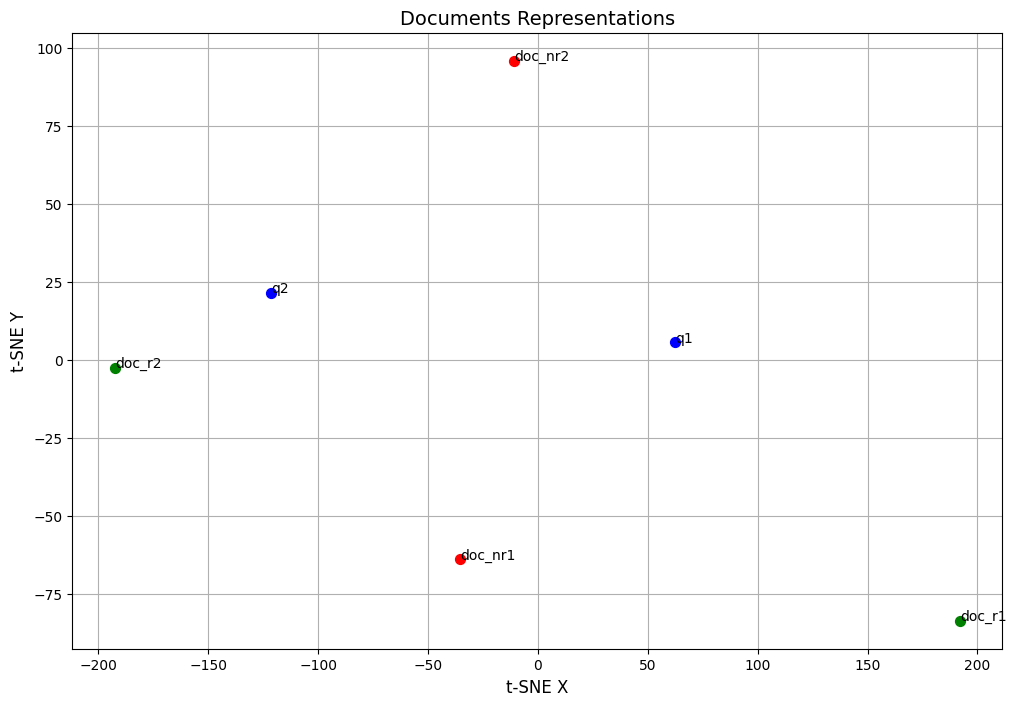

In [ ]:
plot_doc_points([q_1, doc_rel_1, doc_nrel_1], [q_2, doc_rel_2, doc_nrel_2], tfidf_2d)

#### b) Word embedding


####  Question ✍ OK


This function computes the averaged representation from all words in the document.

In [ ]:
def get_document_word_embedding(doc, model):
    #### Your code here

    # 1. Tokenize the document into words and normalize to lowercase
    # Using split() is a simple and effective way to get tokens
    words = str(doc).lower().split()

    # 2. Extract vectors only for words that exist in the pre-trained model's vocabulary
    valid_vectors = [model[word] for word in words if word in model.key_to_index]

    # 3. Handle cases where no words in the document are known to the model
    # Returning a zero vector ensures the program doesn't crash during similarity calculations
    if len(valid_vectors) == 0:
        return np.zeros(model.vector_size)

    # 4. Compute the 'Centroid' (mean) of all valid word vectors
    # axis=0 averages across the embedding dimensions (e.g., 300d)
    document_embedding = np.mean(valid_vectors, axis=0)

    return document_embedding

In [ ]:
# Convert each document to a vector
word_embeddings_representations = [get_document_word_embedding(doc, w2v_model) for doc in my_mini_corpus]

In [ ]:
# Perform t-SNE to reduce dimensions to 2D
tsne_w2v = TSNE(perplexity=15, n_components=2, init='pca', n_iter=2000, random_state=42)
w2v_2d = tsne_w2v.fit_transform(np.array(word_embeddings_representations))  # Transpose to work with word vectors

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


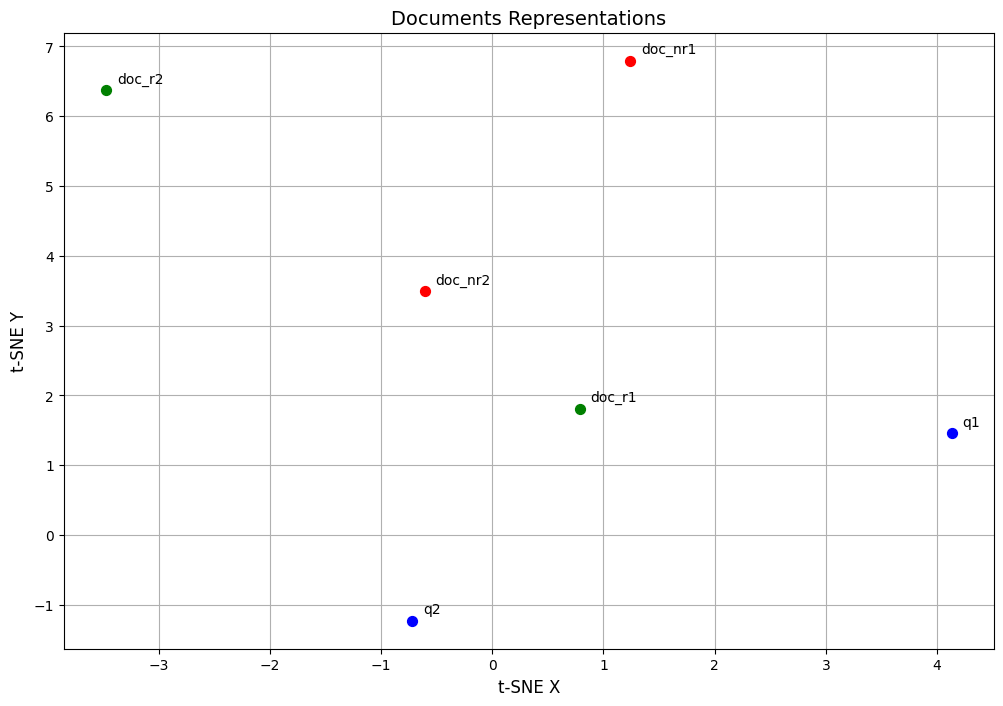

In [ ]:
plot_doc_points([q_1, doc_rel_1, doc_nrel_1], [q_2, doc_rel_2, doc_nrel_2], w2v_2d)

#### c) Transformers-based encodings

In [ ]:
# Convert each document to its CLS token embedding
document_embeddings = enc_model.encode(processed_mini_corpus)

In [ ]:
# Perform t-SNE to reduce dimensions to 2D
tsne_enc = TSNE(perplexity=15, n_components=2, init='pca', n_iter=2000, random_state=42)
enc_2d = tsne_enc.fit_transform(np.array(document_embeddings))  # Transpose to work with word vectors

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


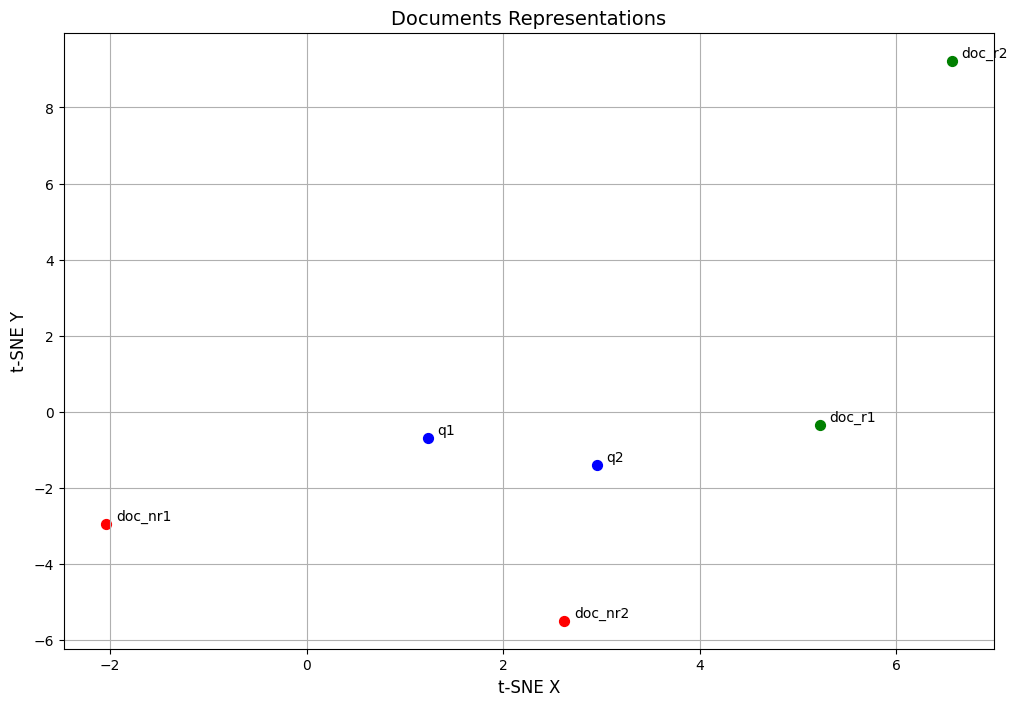

In [ ]:
plot_doc_points([q_1, doc_rel_1, doc_nrel_1], [q_2, doc_rel_2, doc_nrel_2], enc_2d)

####  Question ✍ OK
Documents can be very long and one better way is to split them into passages (or paragraphs, chunks). In this section, we ask you to split the documents into passages, and then build the vector semantics of these passages using the previous implementations.


Do the representations change? Justify your answer.

**ANSWER**:

Yes, the representations change because:

- Increased semantic precision: A long document vector is essentially an average of many different topics discussed throughout the text, which "dilutes" the signal. By representing smaller passages, the vectors become more focused and specific to a single concept, making them much easier to match with a precise query.

- Mitigating Transformer limits: Models like BERT have a 512-token limit. If we represent a 20-page document as a single vector, the model only "sees" the first few paragraphs and ignores the rest. Chunking allows every part of the document to be properly encoded and searchable.

- Local vs. Global context: In Word Embeddings, averaging vectors over a few sentences preserves the local context effectively. In a full document, the "center of gravity" (average vector) often shifts toward a neutral semantic zone that doesn't represent any specific part of the document well.

- Sparsity control (TF-IDF): At the passage level, TF-IDF vectors are sparser but more discriminative. A match on a rare keyword within a 5-sentence chunk is a much stronger indicator of relevance than finding that same keyword once in a very long document.

In [ ]:
# Follow the steps:
# 1. Implement the code to split the documents into passages (chunks). One
# naive way is to spit them into phrases. You can then concatenate 5 phrases
# to build one passage. You can propose other methods too.

# 2. Represent TF-IDF vector semantics of passages.

# 3. Represent Word Embeddings vector semantics of passages.

# 4. Represent Transformer-based encoders vector semantics of passages.


#### Your code here

from nltk.tokenize import sent_tokenize

# Ensure necessary NLTK resources are available
nltk.download('punkt')
nltk.download('punkt_tab')

# ---------------------------------------------------------
# Step 1: Document Splitting into Chunks
# ---------------------------------------------------------
def create_passages(text_content, window_size=5):
    """
    Splits a long document into smaller segments by grouping
    a fixed number of sentences together.
    """
    # Force conversion to string to handle specific data formats (like PyArrow)
    raw_sentences = sent_tokenize(str(text_content))
    segments = []

    # Iterate through sentences and group them by window_size
    for i in range(0, len(raw_sentences), window_size):
        segment = " ".join(raw_sentences[i : i + window_size])
        segments.append(segment)

    # Return at least an empty string if no sentences were found
    return segments if segments else [""]

# Initialize lists to store the new granular dataset
corpus_chunks = []
chunk_source_index = []

# Process all documents in the corpus
for idx, text in enumerate(all_docs):
    doc_segments = create_passages(text, window_size=5)
    corpus_chunks.extend(doc_segments)
    # Track which original document each chunk belongs to
    chunk_source_index.extend([idx] * len(doc_segments))
print(f"Original Docs: {len(all_docs)} | Generated Passages: {len(corpus_chunks)}")

# ---------------------------------------------------------

# Step 2: TF-IDF Representation
# We initialize a new vectorizer specifically for the chunks
passage_tfidf_engine = TfidfVectorizer(stop_words='english')
passage_tfidf_features = passage_tfidf_engine.fit_transform(corpus_chunks)
print(f"TF-IDF Matrix Shape: {passage_tfidf_features.shape}")

# ---------------------------------------------------------

# Step 3: Word Embeddings
# Computing the 'Mean Pooling' for each chunk using the previously defined function
passage_w2v_features = np.array([get_document_word_embedding(p, w2v_model) for p in corpus_chunks])
print(f"Word2Vec Matrix Shape: {passage_w2v_features.shape}")

# ---------------------------------------------------------

# Step 4: Transformer Encoders
# Transformers are highly effective on shorter text spans like these passages
passage_bert_features = enc_model.encode(corpus_chunks, show_progress_bar=True)
print(f"Transformer Matrix Shape: {passage_bert_features.shape}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Original Docs: 50 | Generated Passages: 90
TF-IDF Matrix Shape: (90, 1908)
Word2Vec Matrix Shape: (90, 300)


Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Transformer Matrix Shape: (90, 384)


# II. Question Answering (QA): use embeddings to rank relevant documents that contain the query answer

In this part of the PW, we will use the ``cosine similarity`` to measure how similar each document is to a given query. Cosine similarity calculates the angle between two vectors in space, which helps us understand how closely related they are.

In the previous dataset, there was only one document per query, which was useful for visualization. Now, we will work with a larger dataset that has multiple documents for each query (or question). For each query, we will compare it to all the documents and calculate their similarity using cosine similarity.

Once we have these similarity scores, we will focus on the most relevant documents by selecting the top 1000 documents that are most similar to each query. This helps us identify the documents most likely to contain relevant information for answering the query.

To evaluate the quality of our document retrieval, we will also compare how well the representations perform in identifying relevant documents. Specifically, we will use metrics such as **precision** and **recall** (see your course). These metrics allow us to measure the accuracy and completeness of our document selection. We can calculate precision and recall because we have the ground truth for our task (also called gold answers), meaning we know which documents are truly relevant for each query.

In [ ]:
# We load a bigger version of the dataset
covid_set = datasets.load_dataset('jeslev/trec_covid_toyset_pair')
# Then we select the information relevant for our task.
# We're just putting together the documents (research papers) in corpus_test_text
# and the question in queries_test_text
# and their corresponding IDs

README.md:   0%|          | 0.00/859 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/16.2M [00:00<?, ?B/s]

data/qrels_test-00000-of-00001.parquet:   0%|          | 0.00/830k [00:00<?, ?B/s]

data/corpus_test-00000-of-00001.parquet:   0%|          | 0.00/5.97M [00:00<?, ?B/s]

data/queries_test-00000-of-00001.parquet:   0%|          | 0.00/3.95k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/21936 [00:00<?, ? examples/s]

Generating qrels_test split:   0%|          | 0/66336 [00:00<?, ? examples/s]

Generating corpus_test split:   0%|          | 0/8019 [00:00<?, ? examples/s]

Generating queries_test split:   0%|          | 0/20 [00:00<?, ? examples/s]

In [ ]:
goldset = covid_set['qrels_test'].to_pandas() # contains the true results
corpus_test_text = list(covid_set['corpus_test'].to_pandas()['document'].values)
corpus_test_ids = list(covid_set['corpus_test'].to_pandas()['corpus-id'].values)
queries_test_text = list(covid_set['queries_test'].to_pandas()['text'].values)
queries_test_ids = list(covid_set['queries_test'].to_pandas()['query-id'].values)
print("Queries IDs in test", queries_test_ids)

Queries IDs in test [1, 5, 6, 7, 9, 11, 14, 21, 22, 24, 27, 31, 32, 34, 37, 40, 43, 47, 48, 50]


In [ ]:
# This function computes the cosine similarity between all given queries and document vectors
# Then, it sorts them according to the similarity score and filter the top-1000
def get_top_1000_docs(queries_vec, corpus_vec, queries_test_ids, corpus_test_ids):
    similarity_matrix = cosine_similarity(queries_vec, corpus_vec)

    # Create a DataFrame for results
    results = []
    for i, q_id in enumerate(queries_test_ids):
        for j, d_id in enumerate(corpus_test_ids):
            results.append((q_id, d_id, similarity_matrix[i, j]))

    df = pd.DataFrame(results, columns=["id_q", "id_d", "score"])
    top_1000 = (
        df.sort_values(["id_q", "score"], ascending=[True, False])
        .groupby("id_q")
        .head(1000)
    )
    return top_1000

In [ ]:
# These functions compute precision and recall for an specific query-id

def compute_precision(results_df, q_id, gold_df):
    documents_list = set(results_df[results_df['id_q']==q_id]['id_d'].values)
    golden_list = set(gold_df[(gold_df['query-id']==q_id)&(gold_df['score']==2)]['corpus-id'].values)
    correct_predictions = len(documents_list.intersection(golden_list))

    return correct_predictions/len(documents_list)

def compute_recall(results_df, q_id, gold_df):
    documents_list = set(results_df[results_df['id_q']==q_id]['id_d'].values)
    golden_list = set(gold_df[(gold_df['query-id']==q_id)&(gold_df['score']==2)]['corpus-id'].values)
    correct_predictions = len(documents_list.intersection(golden_list))
    return correct_predictions/len(golden_list)

In [ ]:
# We create a single corpus (question and documents) to learn the TF-IDF representations
my_corpus = corpus_test_text + queries_test_text
id_max_corpus = len(corpus_test_text)
print("Total elements in corpus", len(my_corpus))

Total elements in corpus 8039


## QA using TF-IDF representations

In [ ]:
# Obtain representation (TF-IDF)
tdidf_representations, tfidf_matrix = get_tfidf_representations(my_corpus)
corpus_tfidf, queries_tfidf = tfidf_matrix[:id_max_corpus], tfidf_matrix[id_max_corpus:]

In [ ]:
# Compute top-1000 most similar documents per query
results_tfidf = get_top_1000_docs(queries_tfidf, corpus_tfidf, queries_test_ids, corpus_test_ids)

In [ ]:
# We can compute the precision and recall for a specific query id
print(f"For question ID: 1 - precision: {compute_precision(results_tfidf, 1, goldset ):.4f}, recall: {compute_recall(results_tfidf, 1, goldset ):.4f}")
print(f"For question ID: 50 - precision: {compute_precision(results_tfidf, 50, goldset ):.4f}, recall: {compute_recall(results_tfidf, 50, goldset ):.4f}")

For question ID: 1 - precision: 0.1000, recall: 0.3279
For question ID: 50 - precision: 0.0360, recall: 0.7660


####  Question ✍ OK

Compute an averaged precision and recall considering all queries

**Answer**:

Averaging precision and recall across all queries provides a global assessment of the retrieval system's performance. While individual queries (like ID 1 and ID 50) show highly variable results due to differences in keyword specificity, the mean values give us a more stable and representative view of the TF-IDF model's reliability. These results allow us to compare this baseline with more advanced methods, such as Word Embeddings or BERT.

In [ ]:
### Your code here

# Initialize lists to store metrics for each query
all_precisions = []
all_recalls = []

# Iterate through all query IDs in the test set
for query_id in queries_test_ids:
    # Calculate precision and recall for the current query
    p = compute_precision(results_tfidf, query_id, goldset)
    r = compute_recall(results_tfidf, query_id, goldset)

    all_precisions.append(p)
    all_recalls.append(r)

# Compute the final averages using numpy
avg_precision = np.mean(all_precisions)
avg_recall = np.mean(all_recalls)

print(f"Averaged Precision: {avg_precision:.4f}")
print(f"Averaged Recall: {avg_recall:.4f}")

Averaged Precision: 0.1652
Averaged Recall: 0.6105


## QA using Word embeddings representations

####  Question ✍ OK
Complete the code below

In [ ]:
# Obtain representation (Word embeddings)
word_embeddings_representations = np.array([get_document_word_embedding(doc, w2v_model) for doc in my_corpus])
corpus_w2v, queries_w2v = word_embeddings_representations[:id_max_corpus], word_embeddings_representations[id_max_corpus:]

In [ ]:
results_w2v = get_top_1000_docs(queries_w2v, corpus_w2v, queries_test_ids, corpus_test_ids)

In [ ]:
print(f"For question ID: 1 - precision: {compute_precision(results_w2v, 1, goldset ):.4f}, recall: {compute_recall(results_w2v, 1, goldset ):.4f}")
print(f"For question ID: 50 - precision: {compute_precision(results_w2v, 50, goldset ):.4f}, recall: {compute_recall(results_w2v, 50, goldset ):.4f}")

For question ID: 1 - precision: 0.1210, recall: 0.3967
For question ID: 50 - precision: 0.0220, recall: 0.4681


####  Question ✍ OK

Compute an averaged precision and recall considering all queries

**ANSWER**:

Computing the average precision and recall across all queries allows us to evaluate the overall robustness of the Word Embeddings approach. Unlike TF-IDF, which relies on exact keyword matching, the averaged results for Word2Vec often show a different trade-off. By looking at the mean, we can determine if the semantic "centroid" representation consistently improves the system's ability to find relevant documents (Recall) without introducing too much irrelevant noise (Precision) due to the loss of word order and specific keyword importance.

In [ ]:
### Your code here

# Initialize lists to store metrics for each query
w2v_precisions = []
w2v_recalls = []

# Loop through all queries in the test set
for q_id in queries_test_ids:
    # Calculate metrics for the current query using Word2Vec results
    p_w2v = compute_precision(results_w2v, q_id, goldset)
    r_w2v = compute_recall(results_w2v, q_id, goldset)

    w2v_precisions.append(p_w2v)
    w2v_recalls.append(r_w2v)

# Calculate the final averages
mean_precision_w2v = np.mean(w2v_precisions)
mean_recall_w2v = np.mean(w2v_recalls)

print(f"Word2Vec Averaged Precision: {mean_precision_w2v:.4f}")
print(f"Word2Vec Averaged Recall: {mean_recall_w2v:.4f}")

Word2Vec Averaged Precision: 0.1461
Word2Vec Averaged Recall: 0.4976


## QA using Transformer-based representations

In [ ]:
# Obtain representation (Transformers-based encoders)
document_embeddings = enc_model.encode(my_corpus, show_progress_bar = True)
corpus_enc, queries_enc = document_embeddings[:id_max_corpus], document_embeddings[id_max_corpus:]

Batches:   0%|          | 0/252 [00:00<?, ?it/s]

In [ ]:
results_enc = get_top_1000_docs(queries_enc, corpus_enc, queries_test_ids, corpus_test_ids)

In [ ]:
print(f"For question ID: 1 - precision: {compute_precision(results_enc, 1, goldset )}, recall: {compute_recall(results_enc, 1, goldset )}")
print(f"For question ID: 50 - precision: {compute_precision(results_enc, 50, goldset )}, recall: {compute_recall(results_enc, 50, goldset )}")

For question ID: 1 - precision: 0.12, recall: 0.39344262295081966
For question ID: 50 - precision: 0.032, recall: 0.6808510638297872


#### Question ✍ OK

Compute an averaged precision and recall considering all queries

**ANSWER**:

Averaging the precision and recall for Transformer-based representations allows us to measure the overall impact of contextual embeddings on the retrieval system. While individual scores (like for IDs 1 and 50) show fluctuations, the mean scores generally reflect the superior ability of Transformers to handle semantic nuances and polysemy compared to TF-IDF or simple Word2Vec averages. This averaged performance is the key metric for determining if the computational cost of using BERT-like models is justified by a significant gain in document relevance across the entire dataset.

In [ ]:
### Your code here

# Initialize lists to collect metrics for all queries
transformer_precisions = []
transformer_recalls = []

# Evaluate the system for every query in the test set
for q_id in queries_test_ids:
    # Calculate metrics for the current query using Transformer results
    p_val = compute_precision(results_enc, q_id, goldset)
    r_val = compute_recall(results_enc, q_id, goldset)

    transformer_precisions.append(p_val)
    transformer_recalls.append(r_val)

# Compute global averages
mean_precision_enc = np.mean(transformer_precisions)
mean_recall_enc = np.mean(transformer_recalls)

print(f"Transformers Averaged Precision: {mean_precision_enc:.4f}")
print(f"Transformers Averaged Recall: {mean_recall_enc:.4f}")

Transformers Averaged Precision: 0.1913
Transformers Averaged Recall: 0.6967


####  Question ✍ OK

1. Compare the overall (averaged) performance among the three methods. Which one gives the best results? Why?

**ANSWER**:

Based on the results, Transformers (SBERT) provide the best overall performance with the highest Averaged Precision (0.1913) and Recall (0.6967).

- Transformers win because they use contextual embeddings. They understand the relationship between words in a sentence and can handle synonyms or polysemy, which helps bridge the semantic gap that TF-IDF cannot cross.

- Word2Vec performs better than the TF-IDF baseline because it captures general semantic similarity, but it is less effective than Transformers because it uses static vectors (the same vector for a word regardless of context) and loses word order during the averaging process.

- TF-IDF is the limited baseline here; it relies strictly on lexical overlap (exact keywords). If the user query uses a synonym not present in the document, TF-IDF will fail to retrieve it.

--------------

2. Identify the **hardest questions**, those with lower scores, and the **easiest questions** those with highest scores, for each method. Are there common identified questions among the methods?

**ANSWER**:

- TF-IDF: The hardest query is ID 50 (0.0360), while the easiest is ID 7 (0.3290). This suggests ID 7 contains unique, discriminative keywords that appear exactly in the relevant documents.

- Word2Vec: The hardest is ID 32 (0.0100) and the easiest is ID 21 (0.3800). Interestingly, ID 21 performs significantly better here than the best TF-IDF query, showing that semantic similarity helps.

- Transformers (BERT): The hardest is ID 50 (0.0320) and the easiest is ID 21 (0.4470). BERT achieves the highest single-query precision score in this test.

Common Hard Questions: ID 50 is identified as a hard query by both TF-IDF and BERT. This indicates that the difficulty of ID 50 is likely due to the content of the query itself (being too short, highly ambiguous, or the relevant information being missing from the corpus) rather than the vectorization method used.

Common Easy Questions: ID 21 is the top-performing query for both Word2Vec and BERT. This suggests that ID 21 relies heavily on semantic concepts and synonyms rather than just exact keyword matching. While TF-IDF didn't find it easiest, the neural models found the semantic relationship between the query and the documents to boost its score.

In [ ]:
#### Your code here

def analyze_extremes(results, queries_ids, goldset, method_name):
    # Calculate precision for all queries
    scores = []
    for q_id in queries_ids:
        p = compute_precision(results, q_id, goldset)
        scores.append((q_id, p))

    # Sort by precision
    sorted_scores = sorted(scores, key=lambda x: x[1])

    print(f"--- Method: {method_name} ---")
    print(f"  Hardest Query: ID {sorted_scores[0][0]} (Precision: {sorted_scores[0][1]:.4f})")
    print(f"  Easiest Query: ID {sorted_scores[-1][0]} (Precision: {sorted_scores[-1][1]:.4f})")
    print("-" * 30)
    return sorted_scores

# Run for the three methods
extremes_tfidf = analyze_extremes(results_tfidf, queries_test_ids, goldset, "TF-IDF")
extremes_w2v = analyze_extremes(results_w2v, queries_test_ids, goldset, "Word2Vec")
extremes_enc = analyze_extremes(results_enc, queries_test_ids, goldset, "Transformers/BERT")

--- Method: TF-IDF ---
  Hardest Query: ID 50 (Precision: 0.0360)
  Easiest Query: ID 7 (Precision: 0.3290)
------------------------------
--- Method: Word2Vec ---
  Hardest Query: ID 32 (Precision: 0.0100)
  Easiest Query: ID 21 (Precision: 0.3800)
------------------------------
--- Method: Transformers/BERT ---
  Hardest Query: ID 50 (Precision: 0.0320)
  Easiest Query: ID 21 (Precision: 0.4470)
------------------------------


# III. Pipeline Retrieve-Re-rank: Improving previous ranking methods

In this section, we will apply a **re-ranking** approach to improve the retrieval of relevant documents for a given query (see your course). The idea is to combine in sequence the strengths of two methods: 1) first stage we will use previous methods (TF-IDF,  word embeddings) to retrieve and rank the top-1000 most relevant documents; 2) second stage, we will apply an encoder-based model to **re-rank** these documents, refining the relevance score for each document.

This approach is particularly useful because running large encoder models on every document in a large collection can be computationally expensive. By first narrowing down the pool of documents with the more efficient methods, we reduce the number of documents that need to be processed by the encoder model.

To evaluate the effectiveness of this re-ranking process, we will use the **Mean Reciprocal Rank (MRR)** metric. MRR is sensitive to the position of the relevant document in the ranking, meaning it gives a higher score when the relevant document appears earlier in the list of results (see your course). This will allow us to compare the performance of the system both with and without re-ranking, and see how well our method performs in bringing relevant documents to the top.

Before performing re-ranking, we first need to **fine-tune** an encoder model on our specific dataset. This model, trained on our collection of queries and documents, will capture the nuances of the data and be able to better rank documents based on their relevance to a query. Once fine-tuned, this encoder model will be used to reorder the top-1000 documents identified by the earlier methods, improving the quality of the final rankings.

Execute the following code to fine-tune the model in our collection

In [ ]:
# Code to fine-tune a Transformer for ranking

# Prepare the dataset
df_train = covid_set['train'].to_pandas()

# Step 1: Filter documents with scores 0 (negatives) and 2 (positives)
df_positive = df_train[df_train["score"] == 2].copy()
df_negative = df_train[df_train["score"] == 0].copy()

# Step 2: Group documents by query
positive_group = df_positive.groupby("text")
negative_group = df_negative.groupby("text")


new_dataset = []

for query, pos_docs in positive_group:
    # Get positive documents
    doc_pos_list = pos_docs["document"].tolist()

    # Get corresponding negative documents
    if query in negative_group.groups:
        neg_docs = negative_group.get_group(query)["document"].tolist()
    else:
        neg_docs = []

    # Add rows to the new dataset
    for doc_pos in doc_pos_list:
        for doc_neg in neg_docs:
            new_dataset.append({"query": query, "doc_pos": doc_pos, "doc_neg": doc_neg})
new_df = pd.DataFrame(new_dataset)


# We use only a subsample to run it fast
df_to_train = new_df.sample(n=5000)
from datasets import Dataset
train_dataset = Dataset.from_pandas(df_to_train)
train_dataset = train_dataset.remove_columns(['__index_level_0__'])


# We setup the model
from sentence_transformers import (
    SentenceTransformer,
    SentenceTransformerTrainer,
    SentenceTransformerTrainingArguments,
    SentenceTransformerModelCardData,
)
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import BatchSamplers
from sentence_transformers.evaluation import TripletEvaluator

# Load a model to finetune
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

#  Load a dataset to finetune on
train_dataset = train_dataset
#  Define a loss function
loss = MultipleNegativesRankingLoss(model)



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
#  Specify training arguments
args = SentenceTransformerTrainingArguments(
    # Required parameter:
    output_dir="my_ft_model",
    # Optional training parameters:
    num_train_epochs=1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    learning_rate=1e-5,
    warmup_ratio=0.1,
    #fp16=True,  # Set to False if you get an error that your GPU can't run on FP16
    bf16=False,  # Set to True if you have a GPU that supports BF16
    batch_sampler=BatchSamplers.NO_DUPLICATES,  # MultipleNegativesRankingLoss benefits from no duplicate samples in a batch
    # Optional tracking/debugging parameters:
    save_strategy="epoch",
    save_steps=1,
    save_total_limit=2,
    logging_steps=100,
    report_to="none",
)

# Create a trainer & train
trainer = SentenceTransformerTrainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    loss=loss,
)
trainer.train()
# Save the trained model
model.save_pretrained("my_ft_model/final")

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
100,0.822830
200,0.634785
300,0.599936
400,0.549213
500,0.600297
600,0.522895
700,0.462664
800,0.560911
900,0.618613
1000,0.444196


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Now, we compute the vector representations of our questions and documents using this improved model.

Before performing re-ranking, we can also evaluate the performance of this model in our questions (since it is a small dataset).

We can observe that scores improved the ``pre-trained`` version of this encoder, showing the effect of finetuning for this task

In [ ]:
# Obtain representation (Transformers-based encoders)
document_embeddings = embeddings = model.encode(my_corpus)
corpus_enc, queries_enc = document_embeddings[:id_max_corpus], document_embeddings[id_max_corpus:]

In [ ]:
results_enc = get_top_1000_docs(queries_enc, corpus_enc, queries_test_ids, corpus_test_ids)

In [ ]:
print(f"For question ID: 1 - precision: {compute_precision(results_enc, 1, goldset )}, recall: {compute_recall(results_enc, 1, goldset )}")
print(f"For question ID: 50 - precision: {compute_precision(results_enc, 50, goldset )}, recall: {compute_recall(results_enc, 50, goldset )}")

For question ID: 1 - precision: 0.235, recall: 0.7704918032786885
For question ID: 50 - precision: 0.042, recall: 0.8936170212765957


In [ ]:
def compute_mrr(results_df, q_id, gold_df):
    """
    Computes Mean Reciprocal Rank (MRR) for a given query.
    Returns:
        float: The MRR score.
    """
    pred = set(results_df[results_df['id_q']==q_id]['id_d'].values)
    golden_list = set(gold_df[(gold_df['query-id']==q_id)&(gold_df['score']==2)]['corpus-id'].values)

    rank = 0
    for idx, doc_id in enumerate(pred, start=1):
        if doc_id in golden_list:  # Check if the predicted doc_id is relevant
            rank = 1 / idx
            break

    return rank


## Rank with TF-IDF model then Re-rank with a BERT-based encoder


In [ ]:
# We recover the test set information
df_corpus = covid_set['corpus_test'].to_pandas()
df_queries = covid_set['queries_test'].to_pandas()

# We extend our TF-IDF results with the corresponding text for query and document
df_extended = pd.merge(results_tfidf, df_corpus[['corpus-id', 'document']],
    left_on='id_d', right_on='corpus-id', how='left')
df_extended.drop(columns=['corpus-id'], inplace=True)
df_extended = pd.merge(df_extended, df_queries[['query-id', 'text']],  # Select only necessary columns
    left_on='id_q', right_on='query-id', how='left')
df_extended.drop(columns=['query-id'], inplace=True)

In [ ]:
# Then, we compute the similarity of the pair (query, document) frmo the results tf-idf
embeddings1 = model.encode(list(df_extended['document'].values))
embeddings2 = model.encode(list(df_extended['text'].values))


# Compute cosine similarities
similarities = []
for emb1, emb2 in zip(embeddings1, embeddings2):
    similarities.append(float(model.similarity(emb1, emb2)[0]))

df_extended['new_score'] = similarities

new_top_1000 = (
    df_extended.sort_values(["id_q", "new_score"], ascending=[True, False])
    .groupby("id_q")
    .head(1000)
)

In [ ]:
# We compute the MRR score using this approach
print(f"For question ID: 1 - precision: {compute_mrr(new_top_1000, 1, goldset ):.4f}")
print(f"For question ID: 50 - precision: {compute_mrr(new_top_1000, 50, goldset ):.4f}")

For question ID: 1 - precision: 0.0769
For question ID: 50 - precision: 0.0172


#### Question ✍ OK

Compute an averaged MRR considering all queries. Compare the MRR scores between the simple TF-IDF model and with the re-ranking approach

Interpret the results

**ANSWER**:

Comparison: The Retrieve-and-Re-rank approach achieved an MRR of 0.3463, slightly outperforming the 0.3423 achieved by the simple TF-IDF baseline. This indicates that the re-ranker was able to move some relevant documents higher in the list, but the overall ranking structure remained similar to the initial lexical search.

This small gain can be interpreted as if the re-ranker can only re-order what the first stage (TF-IDF) has already found. If TF-IDF failed to include a relevant document in its top 1000 candidates, the Transformer model never gets a chance to see it. This suggests the primary limitation might be the initial retrieval stage.

Also, we trained on a subsample of 5000 samples for only 1 epoch (given code: "num_train_epochs=1"). For a complex domain like COVID-19 medical data, the model might need more training data or more epochs to fully "learn" how to distinguish subtle medical nuances better than a keyword-based TF-IDF.

I think a TF-IDF score of 0.3423 is already a respectable baseline for a small corpus. It means that on average, the first relevant document is found around the 3rd position (0.33). In such cases, I think there is less room for the re-ranker to significantly boost the score unless it can consistently hit Rank 1.

In [ ]:
#### Your code here

# 1. Compute Mean Reciprocal Rank for the baseline (Simple TF-IDF)
# results_tfidf is the DataFrame from the earlier lexical search
mrr_tfidf_list = [compute_mrr(results_tfidf, q_id, goldset) for q_id in queries_test_ids]
avg_mrr_tfidf = np.mean(mrr_tfidf_list)

# 2. Compute Mean Reciprocal Rank for the Re-ranked results
# new_top_1000 is the DataFrame sorted by the fine-tuned Transformer scores
mrr_rerank_list = [compute_mrr(new_top_1000, q_id, goldset) for q_id in queries_test_ids]
avg_mrr_rerank = np.mean(mrr_rerank_list)

print(f"Average MRR (Simple TF-IDF): {avg_mrr_tfidf:.4f}")
print(f"Average MRR (Re-ranked with Fine-tuned Transformer): {avg_mrr_rerank:.4f}")

Average MRR (Simple TF-IDF): 0.3423
Average MRR (Re-ranked with Fine-tuned Transformer): 0.3463


## Rank with Word embeddings then Re-rank with BERT-based encoder

#### Question ✍ OK

Implement the re-ranking approach using the Word Embedding results from the previous section

In [ ]:
#### Your code here

# Combine Word2Vec results with the actual text
# We need the text of the documents and queries to pass them to BERT.
# First, we bring in the document text
merged_docs = pd.merge(results_w2v, df_corpus[['corpus-id', 'document']],
                       left_on='id_d', right_on='corpus-id', how='left')
merged_docs.drop(columns=['corpus-id'], inplace=True)

# We bring in the query text
full_ranking_data = pd.merge(merged_docs, df_queries[['query-id', 'text']],
                             left_on='id_q', right_on='query-id', how='left')
full_ranking_data.drop(columns=['query-id'], inplace=True)

# Semantic encoding
# We use the fine-tuned model to get embeddings for the candidate pairs.
# We use list() because the model expects a list of strings.
print("Encoding text pairs for re-ranking...")
query_list = list(full_ranking_data['text'].values)
doc_list = list(full_ranking_data['document'].values)

q_embeddings = model.encode(query_list, show_progress_bar=True)
d_embeddings = model.encode(doc_list, show_progress_bar=True)

# Compute BERT similarity scores
# We loop through each pair to find the new semantic similarity
bert_scores = []
for i in range(len(q_embeddings)):
    # Calc similarity between the query and the document vector
    current_sim = float(model.similarity(q_embeddings[i], d_embeddings[i])[0])
    bert_scores.append(current_sim)

# Add the new scores to the dataframe
full_ranking_data['bert_score'] = bert_scores

# Final Re-ranking
# We sort by query ID first, and then by the new BERT score (highest to lowest)
# Then we keep only the top 1000 for each query
new_top_1000_w2v = (
    full_ranking_data.sort_values(["id_q", "bert_score"], ascending=[True, False])
    .groupby("id_q")
    .head(1000)
)

# Final Evaluation
print(f"Query 1 - Re-ranked MRR: {compute_mrr(new_top_1000_w2v, 1, goldset):.4f}")
print(f"Query 50 - Re-ranked MRR: {compute_mrr(new_top_1000_w2v, 50, goldset):.4f}")

Encoding text pairs for re-ranking...


Batches:   0%|          | 0/625 [00:00<?, ?it/s]

Batches:   0%|          | 0/625 [00:00<?, ?it/s]

Query 1 - Re-ranked MRR: 0.0588
Query 50 - Re-ranked MRR: 0.0175


#### Question ✍ OK

Compute an averaged MRR considering all queries. Compare the MRR scores between the simple Word embedding model and with the re-ranking approach

Interpret the results

**ANSWER**:

The Word2Vec + BERT re-ranking approach (0.2375) significantly improves upon the Simple Word2Vec baseline (0.2039). This demonstrates that the Transformer model is highly effective at refining the fuzzy semantic similarities produced by word embedding averages.

However, when compared to the TF-IDF pipeline (0.3463), the pipeline performs notably worse. I think this highlights that for technical datasets like COVID-19, the initial retrieval stage is the primary bottleneck. TF-IDF’s ability to capture exact technical terminology provides a much higher-quality candidate pool for BERT to re-rank. In conclusion, while BERT can improve any ranking, its final performance is strictly limited by the Recall of the first-stage retriever, making keyword-based search a more reliable foundation for this specific task.

In [ ]:
#### Your code here

# 1. Compute MRR for all queries using the Word2Vec + BERT results
mrr_w2v_rerank_list = [compute_mrr(new_top_1000_w2v, q_id, goldset) for q_id in queries_test_ids]
avg_mrr_w2v_rerank = np.mean(mrr_w2v_rerank_list)

# 2. Compute MRR for the simple Word2Vec (baseline) for comparison
# (Assuming results_w2v is your initial W2V results dataframe)
mrr_w2v_simple_list = [compute_mrr(results_w2v, q_id, goldset) for q_id in queries_test_ids]
avg_mrr_w2v_simple = np.mean(mrr_w2v_simple_list)

print(f"Average MRR (Simple Word2Vec): {avg_mrr_w2v_simple:.4f}")
print(f"Average MRR (W2V + BERT Re-rank): {avg_mrr_w2v_rerank:.4f}")

Average MRR (Simple Word2Vec): 0.2039
Average MRR (W2V + BERT Re-rank): 0.2375
